> **언어 전환 & 바로가기**: **🇰🇷 한국어 (현재 폴더: `notebooks/ko/`)** · [🇺🇸 English (`notebooks/en/stage3_property_graph_bigquery_spanner_en.ipynb`)](../en/stage3_property_graph_bigquery_spanner_en.ipynb) ｜ [방법론 가이드 (Methodology Doc)](../../methodology/ko/03_stage3_property_graph_ko.md) ｜ [노트북 전체 인덱스 (README)](../README.md) ｜ [라이브 스튜디오 탭 열기](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage3)
>
> **전체 라이프사이클 네비게이션**: [0. 전체 흐름 개요](./stage0_overview_walkthrough_ko.ipynb) → [Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb) → [Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb) → **[▶ Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb)** → [Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb) → [Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb)

---

# Stage 3. [구축] Zero-ETL 물리 프로퍼티 그래프 (BigQuery Graph / Spanner Graph) & 바인딩 변수 기반 ISO GQL
## Step 3.1 6 Node × 4 Edge 그래프 메타모델 설계 및 DDL 프로비저닝 · Step 3.2 인스턴스 토폴로지 시각화 및 ISO GQL / NL2GQL

Stage 3은 방법론의 **Phase 5(물리 그래프 구축)**를 구현합니다. Stage 1·2에서 적재한 BigQuery 10개 테이블을 별도 복제 없이(**Zero-ETL**) `pipeline/graph_builder.py`를 통해 **6개 노드 레이블(`CustomerContractNode`, `DeviceNode`, `PlanNode`, `SubsidyNode`, `DomainRuleNode`, `DocChunkNode`)**과 **4개 엣지 레이블(`USES_DEVICE`, `SUBSCRIBES_PLAN`, `HAS_SUBSIDY_POLICY`, `APPLIES_TO_PLAN`)**을 가진 `STARTER_ONTOLOGY_GRAPH`로 선언하고, **바인딩 변수 명세와 실행 ISO GQL 문장**을 투명하게 확인하며 다중 홉 탐색과 Gemini 기반 자연어→GQL 변환(`nl2gql`)을 수행합니다.

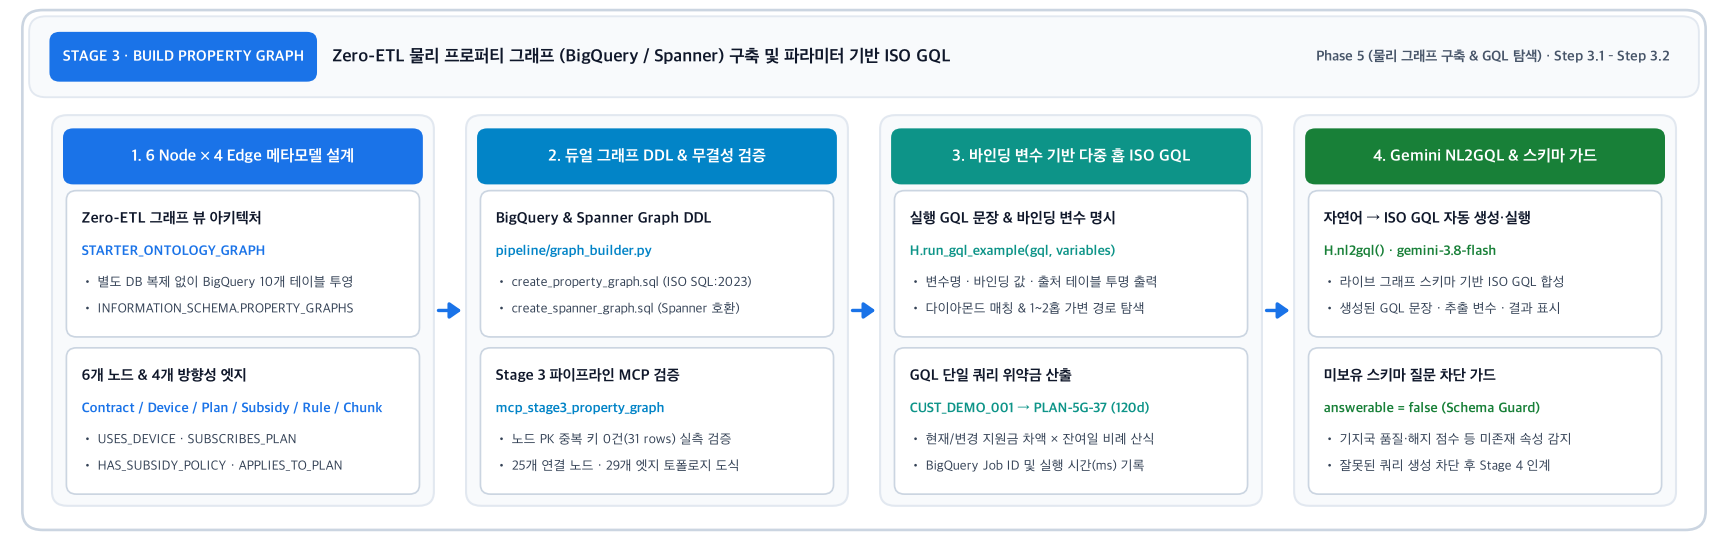


In [1]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
H.setup("ko")
server = DomainMcpServer()


### 1. [Phase 5a: 그래프 스키마 설계 및 메타모델 도식] `INFORMATION_SCHEMA.PROPERTY_GRAPHS` 라이브 메타데이터 및 6 Node × 4 Edge 설계도


**Live Property Graph Catalog Job**: `job_kvdJNr5cd0CXT-iX5IUI-IJ_dSEV` (636.84 ms) · Nodes `6` · Edges `4`

,label,table,key,properties
0,CustomerContractNode,tb_customer_contract,contract_id,"[contract_id:STRING, customer_id:STRING, customer_segment:STRING, age_group:STRING, de..."
1,DeviceNode,tb_device_master,device_id,"[device_id:STRING, device_name:STRING, manufacturer:STRING, storage_gb:INT64, factory_..."
2,PlanNode,tb_plan_master,plan_id,"[plan_id:STRING, plan_name:STRING, tier_category:STRING, monthly_fee_krw:INT64, min_ma..."
3,SubsidyNode,tb_subsidy_policy,policy_id,"[policy_id:STRING, device_id:STRING, plan_id:STRING, base_subsidy_krw:INT64, additiona..."
4,DocChunkNode,tb_doc_chunks,chunk_id,"[chunk_id:STRING, source_file:STRING, section_title:STRING, content:STRING, content_sh..."
5,DomainRuleNode,tb_domain_rules,rule_id,"[rule_id:STRING, rule_name:STRING, rule_category:STRING, condition_expr:STRING, formul..."


,label,table,source,destination,properties
0,USES_DEVICE,edge_contract_device,CustomerContractNode,DeviceNode,"[contract_id:STRING, customer_id:STRING, device_id:STRING, edge_type:STRING]"
1,SUBSCRIBES_PLAN,edge_contract_plan,CustomerContractNode,PlanNode,"[contract_id:STRING, customer_id:STRING, plan_id:STRING, edge_type:STRING]"
2,HAS_SUBSIDY_POLICY,edge_subsidy_binding,DeviceNode,PlanNode,"[policy_id:STRING, device_id:STRING, plan_id:STRING, total_subsidy_krw:INT64, edge_typ..."
3,APPLIES_TO_PLAN,edge_rule_applies_to_plan,DomainRuleNode,PlanNode,"[edge_id:STRING, rule_id:STRING, plan_id:STRING, source_chunk_id:STRING, relation_labe..."


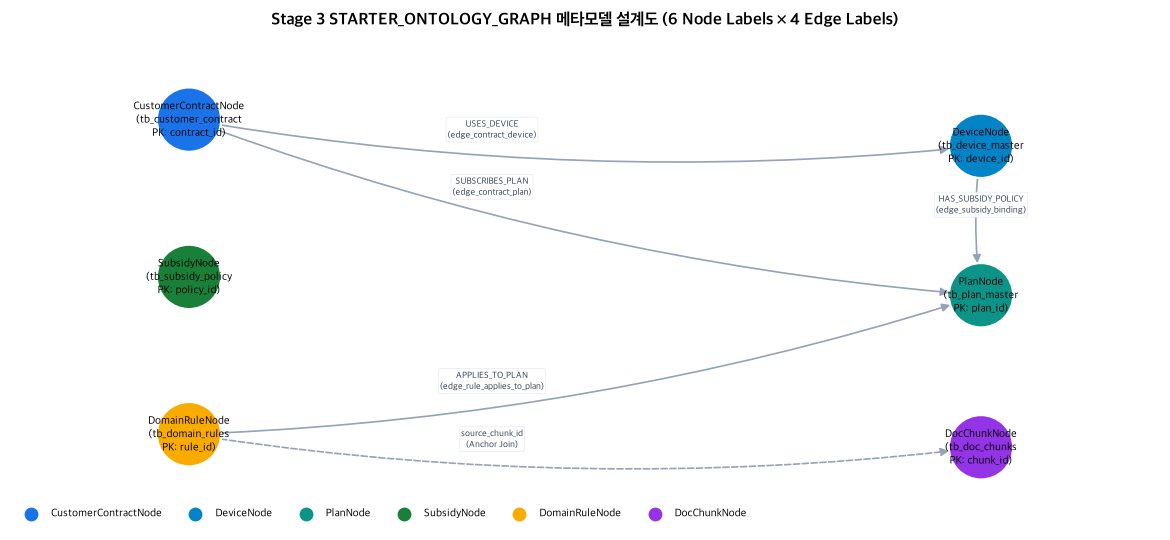

In [2]:
node_labels, edge_labels, meta = H.graph_metadata()
H.md(f"**Live Property Graph Catalog Job**: `{meta['job_id']}` ({meta['elapsed_ms']} ms) · Nodes `{len(node_labels)}` · Edges `{len(edge_labels)}`")
H.show(pd.DataFrame(node_labels))
H.show(pd.DataFrame(edge_labels))
H.draw_property_graph_metamodel()


### 2. [Phase 5b: 듀얼 엔진 DDL 구축 및 무결성 검증] BigQuery Graph / Spanner Graph DDL 비교 및 `mcp_stage3_property_graph` 실행


In [3]:
H.show_md_file(H.ROOT / "data/output/create_property_graph.sql", max_lines=38)
H.show_md_file(H.ROOT / "data/output/create_spanner_graph.sql", max_lines=38)
res_s3 = server.execute_tool("mcp_stage3_property_graph", {"steps": ["promote_dw_nodes", "synthesize_graph_ddl", "verify_gql_templates"]})
H.show_tool(res_s3, "node_tables")
H.show(pd.DataFrame([res_s3["gql_paths"]]))


**`create_property_graph.sql`** (55 lines)

-- [Engine 1: BigQuery Property Graph] ISO SQL:2023 Property Graph DDL
-- Target Dataset: seanjung-poc.starter_ontology_dw (Provisioned via HashiCorp Terraform 1.8.5)
CREATE OR REPLACE PROPERTY GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  NODE TABLES (
    `seanjung-poc.starter_ontology_dw.tb_customer_contract`
      KEY (contract_id)
      LABEL CustomerContractNode
      PROPERTIES (contract_id, customer_id, customer_segment, age_group, device_id, plan_id, contract_type, commitment_months, elapsed_days, granted_subsidy_krw, welfare_status, status, provenance, source_ref),
    `seanjung-poc.starter_ontology_dw.tb_device_master`
      KEY (device_id)
      LABEL DeviceNode
      PROPERTIES (device_id, device_name, manufacturer, storage_gb, factory_price_krw, release_date, provenance, source_ref),
    `seanjung-poc.starter_ontology_dw.tb_plan_master`
      KEY (plan_id)
      LABEL PlanNode
      PROPERTIES (plan_id, plan_name, tier_category, monthly_fee_krw, min_maintenance_days, selective_discount_rate, provenance, source_ref),
    `seanjung-poc.starter_ontology_dw.tb_subsidy_policy`
      KEY (policy_id)
      LABEL SubsidyNode
      PROPERTIES (policy_id, device_id, plan_id, base_subsidy_krw, additional_subsidy_cap_krw, mandatory_retention_days, effective_from, provenance, source_ref),
    `seanjung-poc.starter_ontology_dw.tb_doc_chunks`
      KEY (chunk_id)
      LABEL DocChunkNode
      PROPERTIES (chunk_id, source_file, section_title, content, content_sha256, trust_tier),
    `seanjung-poc.starter_ontology_dw.tb_domain_rules`
      KEY (rule_id)
      LABEL DomainRuleNode
      PROPERTIES (rule_id, rule_name, rule_category, condition_expr, formula_expr, source_chunk_id, description_ko, provenance, source_ref)
  )
  EDGE TABLES (
    `seanjung-poc.starter_ontology_dw.edge_contract_device`
      KEY (contract_id, device_id)
      SOURCE KEY (contract_id) REFERENCES `seanjung-poc.starter_ontology_dw.tb_customer_contract` (contract_id)
      DESTINATION KEY (device_id) REFERENCES `seanjung-poc.starter_ontology_dw.tb_device_master` (device_id)
      LABEL USES_DEVICE
      PROPERTIES (contract_id, customer_id, device_id, edge_type),
    `seanjung-poc.starter_ontology_dw.edge_contract_plan`
      KEY (contract_id, plan_id)

**`create_spanner_graph.sql`** (167 lines)

-- [Engine 2: Cloud Spanner Graph] ISO GQL Property Graph Schema & DDL
-- Target Instance/DB: projects/seanjung-poc/instances/starter-spanner/databases/starter_ontology_db
-- Architecture: Low-Latency Online Graph Traversal on Cloud Spanner (Enterprise 100 PU) + BigQuery Graph Fabric (EXTERNAL_QUERY)

CREATE TABLE tb_device_master (
  device_id STRING(64) NOT NULL,
  device_name STRING(256) NOT NULL,
  manufacturer STRING(128) NOT NULL,
  storage_gb INT64 NOT NULL,
  factory_price_krw INT64 NOT NULL,
  release_date STRING(32),
  provenance STRING(64),
  source_ref STRING(256)
) PRIMARY KEY (device_id);

CREATE TABLE tb_plan_master (
  plan_id STRING(64) NOT NULL,
  plan_name STRING(256) NOT NULL,
  tier_category STRING(64) NOT NULL,
  monthly_fee_krw INT64 NOT NULL,
  min_maintenance_days INT64 NOT NULL,
  selective_discount_rate FLOAT64 NOT NULL,
  provenance STRING(64),
  source_ref STRING(256)
) PRIMARY KEY (plan_id);

CREATE TABLE tb_subsidy_policy (
  policy_id STRING(64) NOT NULL,
  device_id STRING(64) NOT NULL,
  plan_id STRING(64) NOT NULL,
  base_subsidy_krw INT64 NOT NULL,
  additional_subsidy_cap_krw INT64 NOT NULL,
  mandatory_retention_days INT64 NOT NULL,
  effective_from STRING(32),
  provenance STRING(64),
  source_ref STRING(256)
) PRIMARY KEY (policy_id);


**`mcp_stage3_property_graph`** · engine `bigquery` · status `SUCCESS` · steps `promote_dw_nodes, synthesize_graph_ddl, verify_gql_templates` · jobs 2 (1,059.7 ms)

[BIGQUERY] 노드 테이블 중복 키 0건 · GQL 경로(Device→Plan←Rule) 10개

- `job_vDdREUnw75jNSnG9F9FW1dq_kZBk`
- `job_dlkc22u6sLSblx9KlRg6V4qnXg55`

,node_table,row_count,duplicate_keys
0,tb_device_master,4,0
1,tb_plan_master,6,0
2,tb_subsidy_policy,5,0
3,tb_customer_contract,6,0
4,tb_doc_chunks,5,0
5,tb_domain_rules,4,0


,device_plan_rule_paths,subsidy_edges
0,10,5


### 3. [Phase 5c: 물리 그래프 데이터 확인 및 토폴로지 도식] 노드 · 엣지 레이블 분포(`%%bqsql`) 및 전체 인스턴스 토폴로지 시각화


In [4]:
%%bqsql df_gnodes
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (n)
RETURN LABELS(n)[OFFSET(0)] AS label, COUNT(*) AS nodes
GROUP BY label
ORDER BY nodes DESC


,label,nodes
0,PlanNode,6
1,CustomerContractNode,6
2,SubsidyNode,5
3,DocChunkNode,5
4,DeviceNode,4
5,DomainRuleNode,4


In [5]:
%%bqsql df_gedges
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH ()-[e]->()
RETURN LABELS(e)[OFFSET(0)] AS label, COUNT(*) AS edges
GROUP BY label
ORDER BY edges DESC


,label,edges
0,APPLIES_TO_PLAN,12
1,SUBSCRIBES_PLAN,6
2,USES_DEVICE,6
3,HAS_SUBSIDY_POLICY,5


In [6]:
%%bqsql df_all_paths
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (a)-[e]->(b)
RETURN TO_JSON(p) AS path


,path
0,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
1,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
2,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
3,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
4,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
5,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
6,"""[{\""identifier\"":\""rh4AAAANAAAApgEAAAAAAAAArA..."
7,"""[{\""identifier\"":\""rh4AAAANAAAApgEAAAAAAAAArA..."
8,"""[{\""identifier\"":\""rh4AAAANAAAApgEAAAAAAAAArA..."
9,"""[{\""identifier\"":\""rh4AAAANAAAApgEAAAAAAAAArA..."


**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | 대상 BigQuery Property Graph 식별자 |
| `pattern (n) / (a)-[e]->(b)` | `ALL_LABELS (6N × 4E)` | 전체 노드·엣지 레이블 스캔 및 JSON 경로 추출 |

**실행된 ISO GQL 문장 (Executed ISO GQL Statements)**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (a)-[e]->(b)
RETURN TO_JSON(p) AS path
```

,label,nodes
0,PlanNode,6
1,CustomerContractNode,6
2,SubsidyNode,5
3,DocChunkNode,5
4,DeviceNode,4
5,DomainRuleNode,4


,label,edges
0,APPLIES_TO_PLAN,12
1,SUBSCRIBES_PLAN,6
2,USES_DEVICE,6
3,HAS_SUBSIDY_POLICY,5


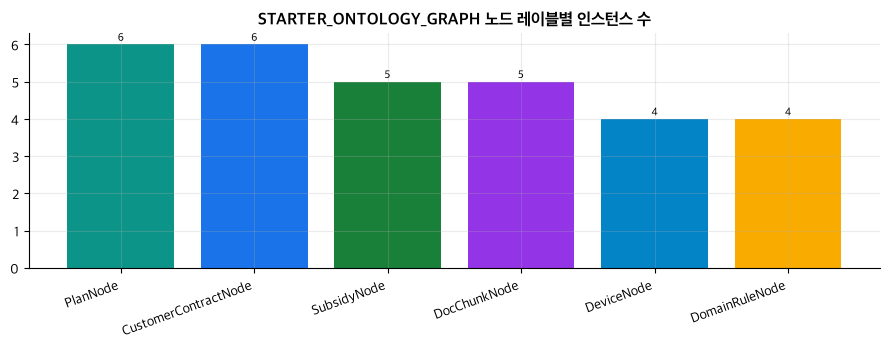

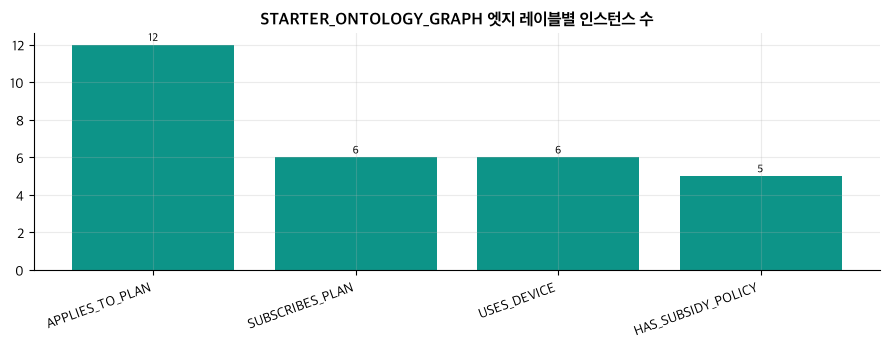

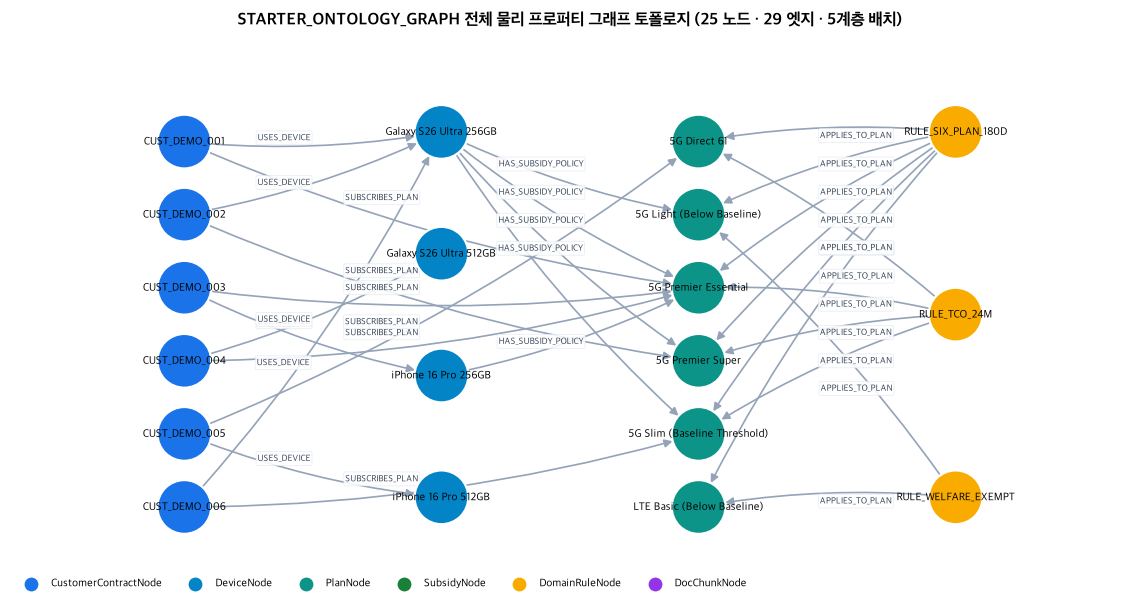

In [7]:
H.md(H._format_vars_md({
    "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "대상 BigQuery Property Graph 식별자"),
    "pattern (n) / (a)-[e]->(b)": ("ALL_LABELS (6N × 4E)", "전체 노드·엣지 레이블 스캔 및 JSON 경로 추출"),
}) + "**" + "실행된 ISO GQL 문장 (Executed ISO GQL Statements)" + "**\n```sql\n"
f"GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`\nMATCH p = (a)-[e]->(b)\nRETURN TO_JSON(p) AS path\n```")
H.show(df_gnodes)
H.show(df_gedges)
H.bar(df_gnodes, "label", "nodes", "STARTER_ONTOLOGY_GRAPH 노드 레이블별 인스턴스 수",
      color=[H.LABEL_COLORS.get(x, "#1A73E8") for x in H.pdf(df_gnodes)["label"]])
H.bar(df_gedges, "label", "edges", "STARTER_ONTOLOGY_GRAPH 엣지 레이블별 인스턴스 수", color="#0d9488")
nodes, edges = H.paths_to_graph(H.pdf(df_all_paths)["path"])
H.draw_graph(nodes, edges, "STARTER_ONTOLOGY_GRAPH 전체 물리 프로퍼티 그래프 토폴로지 (25 노드 · 29 엣지 · 5계층 배치)", legend=H.LABEL_COLORS)


### 4. [Phase 5d: 바인딩 변수 기반 다중 홉 ISO GQL 탐색 실습 (`H.run_gql`)] 실행 GQL 문장 · 바인딩 변수 · 결과 테이블 및 1~2홉 서브그래프 도식


In [8]:
# GQL-01: 2-Hop Customer Contract -> Device & Subscribed Plan
gql_1 = """GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode),
      (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)
RETURN c.customer_id AS customer_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days,
       d.device_name AS device_name, p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw
ORDER BY customer_id"""
df_g1, _ = H.run_gql(
    gql_1,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "프로퍼티 그래프 뷰"),
        "edge_1": ("USES_DEVICE", "CustomerContractNode → DeviceNode (edge_contract_device)"),
        "edge_2": ("SUBSCRIBES_PLAN", "CustomerContractNode → PlanNode (edge_contract_plan)"),
    },
    title="GQL-01 · 고객 약정 중심 단말기 및 가입 요금제 2-Hop 탐색",
)

# GQL-02: Diamond Pattern (Contract -> Device -> Subsidy -> Plan <- Contract)
gql_3 = """GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[:SUBSCRIBES_PLAN]-(c)
RETURN c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name,
       hs.total_subsidy_krw AS policy_total_subsidy_krw, c.granted_subsidy_krw AS granted_subsidy_krw
ORDER BY customer_id"""
df_g3, _ = H.run_gql(
    gql_3,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "프로퍼티 그래프 뷰"),
        "pattern": ("(c)-[:USES_DEVICE]->(d)-[hs:HAS_SUBSIDY_POLICY]->(p)<-[:SUBSCRIBES_PLAN]-(c)",
                    "4개 엔티티 간 다이아몬드(폐루프) 정합성 매칭"),
    },
    title="GQL-02 · 다이아몬드 패턴 매칭 (약정 지급 지원금 vs 정책 고시 총지원금 대조)",
)


#### GQL-01 · 고객 약정 중심 단말기 및 가입 요금제 2-Hop 탐색
- **BigQuery ISO GQL Execution**: status `SUCCESS` · job `job_T7QSetxgO2H410dRwYo7J0asDwPI` · `537 ms` · `6 rows`

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | 프로퍼티 그래프 뷰 |
| `edge_1` | `USES_DEVICE` | CustomerContractNode → DeviceNode (edge_contract_device) |
| `edge_2` | `SUBSCRIBES_PLAN` | CustomerContractNode → PlanNode (edge_contract_plan) |

**2) 실행된 ISO GQL 문장 (Executed ISO GQL Statement)**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode),
      (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)
RETURN c.customer_id AS customer_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days,
       d.device_name AS device_name, p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw
ORDER BY customer_id
```

,customer_id,welfare_status,elapsed_days,device_name,plan_name,monthly_fee_krw
0,CUST_DEMO_001,NONE,120,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CUST_DEMO_002,NONE,224,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CUST_DEMO_003,SENIOR_EXEMPT,88,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CUST_DEMO_004,NONE,109,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CUST_DEMO_005,MILITARY_PAUSE_ELIGIBLE,57,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CUST_DEMO_006,NONE,170,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


#### GQL-02 · 다이아몬드 패턴 매칭 (약정 지급 지원금 vs 정책 고시 총지원금 대조)
- **BigQuery ISO GQL Execution**: status `SUCCESS` · job `job_2uFG9RIpNStwKQusXzCsWcE6X2KI` · `512 ms` · `4 rows`

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | 프로퍼티 그래프 뷰 |
| `pattern` | `(c)-[:USES_DEVICE]->(d)-[hs:HAS_SUBSIDY_POLICY]->(p)<-[:SUBSCRIBES_PLAN]-(c)` | 4개 엔티티 간 다이아몬드(폐루프) 정합성 매칭 |

**2) 실행된 ISO GQL 문장 (Executed ISO GQL Statement)**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[:SUBSCRIBES_PLAN]-(c)
RETURN c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name,
       hs.total_subsidy_krw AS policy_total_subsidy_krw, c.granted_subsidy_krw AS granted_subsidy_krw
ORDER BY customer_id
```

,customer_id,device_name,plan_name,policy_total_subsidy_krw,granted_subsidy_krw
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,517500,517500
1,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,575000,575000
2,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,460000,460000
3,CUST_DEMO_006,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),345000,345000


In [9]:
# GQL-03: Plan-to-DomainRule & SHA-256 DocChunk Anchor Join
target_plan_for_rules = "PLAN-5G-37"
gql_6 = f"""GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (r:DomainRuleNode)-[a:APPLIES_TO_PLAN]->(p:PlanNode),
      (ch:DocChunkNode)
WHERE p.plan_id = '{target_plan_for_rules}' AND ch.chunk_id = a.source_chunk_id
RETURN r.rule_id AS rule_id, a.relation_label_ko AS relation_label_ko, p.plan_name AS plan_name,
       ch.chunk_id AS chunk_id, ch.section_title AS section_title, SUBSTR(ch.content, 1, 90) AS excerpt
ORDER BY rule_id"""
df_g6, _ = H.run_gql(
    gql_6,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "프로퍼티 그래프 뷰"),
        "$target_plan_id (p.plan_id)": (f"'{target_plan_for_rules}'", "PlanNode 요금제 ID 필터 변수"),
        "ch.chunk_id": ("a.source_chunk_id", "APPLIES_TO_PLAN 엣지 ↔ DocChunkNode 앵커 조인"),
    },
    title="GQL-03 · 요금제 바인딩 도메인 규칙 및 원문 정책 청크(SHA-256) 결합 조회",
)

# GQL-04: Single-Query Prorated Subsidy Clawback Calculation
cust_id_param = "CUST_DEMO_001"
target_plan_param = "PLAN-5G-37"
elapsed_days_param = 120
gql_8 = f"""GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode)-[cur:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[:SUBSCRIBES_PLAN]-(c),
      (d)-[tgt:HAS_SUBSIDY_POLICY]->(t:PlanNode),
      (s1:SubsidyNode), (s2:SubsidyNode)
WHERE c.customer_id = '{cust_id_param}' AND t.plan_id = '{target_plan_param}'
  AND s1.policy_id = cur.policy_id AND s2.policy_id = tgt.policy_id
RETURN c.customer_id AS customer_id, p.plan_name AS current_plan, t.plan_name AS target_plan,
       s1.base_subsidy_krw AS current_base_subsidy_krw, s2.base_subsidy_krw AS target_base_subsidy_krw,
       s1.mandatory_retention_days AS retention_days, {elapsed_days_param} AS elapsed_days,
       CAST(ROUND((s1.base_subsidy_krw - s2.base_subsidy_krw) * (s1.mandatory_retention_days - {elapsed_days_param}) / s1.mandatory_retention_days) AS INT64) AS penalty_krw"""
df_g8, _ = H.run_gql(
    gql_8,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "프로퍼티 그래프 뷰"),
        "$customer_id (c.customer_id)": (f"'{cust_id_param}'", "조회 대상 고객 ID (CustomerContractNode)"),
        "$target_plan_id (t.plan_id)": (f"'{target_plan_param}'", "하향 변경 대상 요금제 ID (PlanNode)"),
        "$elapsed_days": (str(elapsed_days_param), "개통 후 경과일수 (180일 기준 일할 산식 변수)"),
    },
    title="GQL-04 · 단일 ISO GQL 쿼리 기반 요금제 하향 차액정산 위약금 산출",
)


#### GQL-03 · 요금제 바인딩 도메인 규칙 및 원문 정책 청크(SHA-256) 결합 조회
- **BigQuery ISO GQL Execution**: status `SUCCESS` · job `job_6m8OtLWb4SG_SCwQFbWgCYmnPmCn` · `572 ms` · `2 rows`

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | 프로퍼티 그래프 뷰 |
| `$target_plan_id (p.plan_id)` | `'PLAN-5G-37'` | PlanNode 요금제 ID 필터 변수 |
| `ch.chunk_id` | `a.source_chunk_id` | APPLIES_TO_PLAN 엣지 ↔ DocChunkNode 앵커 조인 |

**2) 실행된 ISO GQL 문장 (Executed ISO GQL Statement)**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (r:DomainRuleNode)-[a:APPLIES_TO_PLAN]->(p:PlanNode),
      (ch:DocChunkNode)
WHERE p.plan_id = 'PLAN-5G-37' AND ch.chunk_id = a.source_chunk_id
RETURN r.rule_id AS rule_id, a.relation_label_ko AS relation_label_ko, p.plan_name AS plan_name,
       ch.chunk_id AS chunk_id, ch.section_title AS section_title, SUBSTR(ch.content, 1, 90) AS excerpt
ORDER BY rule_id
```

,rule_id,relation_label_ko,plan_name,chunk_id,section_title,excerpt
0,RULE_SIX_PLAN_180D,기준선 미만 하향 시 일할 위약금 발생,5G Light (Below Baseline),DOC_CHUNK_003,Penalty Math Formula,## 3. Penalty Settlement Computation Formula\nThe subsidy difference penalty is calcul...
1,RULE_WELFARE_EXEMPT,시니어 복지 전환 시 위약금 면제 특례,5G Light (Below Baseline),DOC_CHUNK_004,Statutory Penalty Exemptions,## 4. Statutory Penalty Exemption Clauses (위약금 면제 특례 규정)\n1. **Senior & Social Welfare...


#### GQL-04 · 단일 ISO GQL 쿼리 기반 요금제 하향 차액정산 위약금 산출
- **BigQuery ISO GQL Execution**: status `SUCCESS` · job `job_WDdIH-VHF30qfA1yPob5RVZ0_VZU` · `507 ms` · `1 rows`

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | 프로퍼티 그래프 뷰 |
| `$customer_id (c.customer_id)` | `'CUST_DEMO_001'` | 조회 대상 고객 ID (CustomerContractNode) |
| `$target_plan_id (t.plan_id)` | `'PLAN-5G-37'` | 하향 변경 대상 요금제 ID (PlanNode) |
| `$elapsed_days` | `120` | 개통 후 경과일수 (180일 기준 일할 산식 변수) |

**2) 실행된 ISO GQL 문장 (Executed ISO GQL Statement)**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode)-[cur:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[:SUBSCRIBES_PLAN]-(c),
      (d)-[tgt:HAS_SUBSIDY_POLICY]->(t:PlanNode),
      (s1:SubsidyNode), (s2:SubsidyNode)
WHERE c.customer_id = 'CUST_DEMO_001' AND t.plan_id = 'PLAN-5G-37'
  AND s1.policy_id = cur.policy_id AND s2.policy_id = tgt.policy_id
RETURN c.customer_id AS customer_id, p.plan_name AS current_plan, t.plan_name AS target_plan,
       s1.base_subsidy_krw AS current_base_subsidy_krw, s2.base_subsidy_krw AS target_base_subsidy_krw,
       s1.mandatory_retention_days AS retention_days, 120 AS elapsed_days,
       CAST(ROUND((s1.base_subsidy_krw - s2.base_subsidy_krw) * (s1.mandatory_retention_days - 120) / s1.mandatory_retention_days) AS INT64) AS penalty_krw
```

,customer_id,current_plan,target_plan,current_base_subsidy_krw,target_base_subsidy_krw,retention_days,elapsed_days,penalty_krw
0,CUST_DEMO_001,5G Premier Essential,5G Light (Below Baseline),450000,150000,180,120,100000


#### GQL-05 · CUST_DEMO_001 중심 1~2홉 가변 길이 서브그래프 경로 추출
- **BigQuery ISO GQL Execution**: status `SUCCESS` · job `job_AHaFuw9E0ELBTdTFJbqWhGXjcxD9` · `937 ms` · `16 rows`

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | 프로퍼티 그래프 뷰 |
| `$customer_id (c.customer_id)` | `'CUST_DEMO_001'` | 중심 노드(Ego) 고객 ID |
| `quantifier -{1,2}-` | `1..2 hops` | ISO GQL 가변 길이 경로 탐색 범위 |

**2) 실행된 ISO GQL 문장 (Executed ISO GQL Statement)**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (c:CustomerContractNode)-[e]-{1,2}(n)
WHERE c.customer_id = 'CUST_DEMO_001'
RETURN LABELS(n)[OFFSET(0)] AS reached_label, PATH_LENGTH(p) AS hops, TO_JSON(p) AS path
ORDER BY hops, reached_label
```

,reached_label,hops
0,DeviceNode,1
1,PlanNode,1
2,CustomerContractNode,2
3,CustomerContractNode,2
4,CustomerContractNode,2
5,CustomerContractNode,2
6,CustomerContractNode,2
7,CustomerContractNode,2
8,DeviceNode,2
9,DeviceNode,2


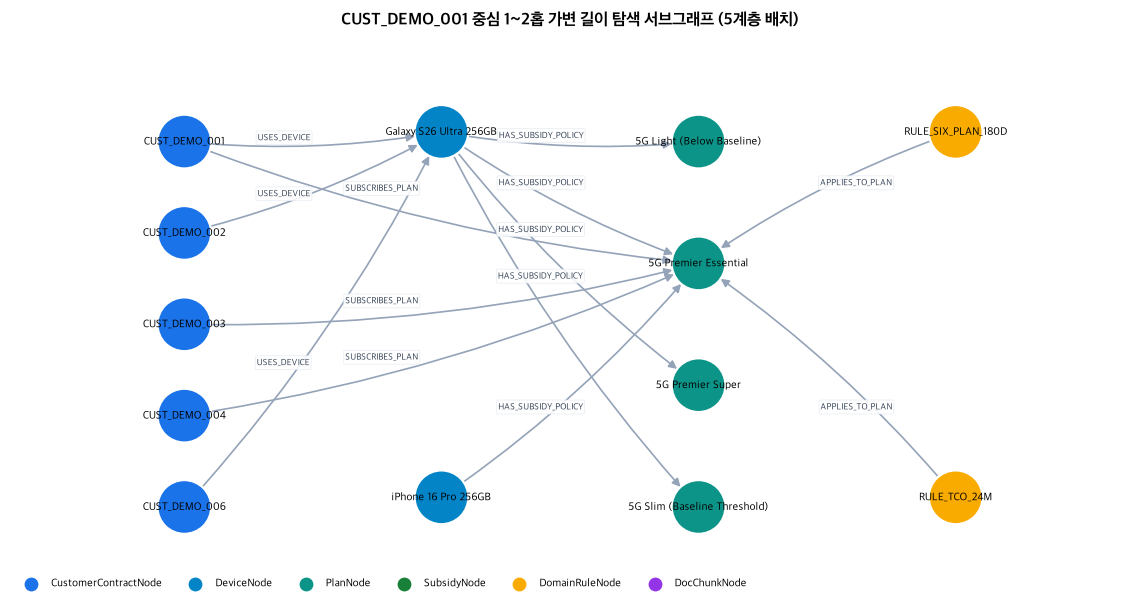

In [10]:
# GQL-05: 1..2-Hop Variable-Length Ego Subgraph for CUST_DEMO_001
ego_customer = "CUST_DEMO_001"
gql_5 = f"""GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (c:CustomerContractNode)-[e]-{{1,2}}(n)
WHERE c.customer_id = '{ego_customer}'
RETURN LABELS(n)[OFFSET(0)] AS reached_label, PATH_LENGTH(p) AS hops, TO_JSON(p) AS path
ORDER BY hops, reached_label"""
df_g5, _ = H.run_gql(
    gql_5,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "프로퍼티 그래프 뷰"),
        "$customer_id (c.customer_id)": (f"'{ego_customer}'", "중심 노드(Ego) 고객 ID"),
        "quantifier -{1,2}-": ("1..2 hops", "ISO GQL 가변 길이 경로 탐색 범위"),
    },
    title="GQL-05 · CUST_DEMO_001 중심 1~2홉 가변 길이 서브그래프 경로 추출",
    show_df=False,
)
H.show(df_g5[["reached_label", "hops"]])
enodes, eedges = H.paths_to_graph(H.pdf(df_g5)["path"])
H.draw_graph(enodes, eedges, "CUST_DEMO_001 중심 1~2홉 가변 길이 탐색 서브그래프 (5계층 배치)", legend=H.LABEL_COLORS)


### 5. [Phase 5e: 자연어 → ISO GQL 변환(`nl2gql`) 및 스키마 가드 검증] Vertex AI Gemini(`gemini-3.8-flash`) 기반 GQL 문장 · 바인딩 변수 생성 및 실행


In [11]:
schema_str = H.schema_text(node_labels, edge_labels)
questions = [
    "고객 계약별로 사용 중인 단말기 이름과 가입 요금제 이름, 월정액을 조회해줘.",
    "요금제별로 연결된 도메인 규칙(DomainRuleNode) 개수와 규칙 ID 목록을 월정액 내림차순으로 보여줘.",
    "2025년 8월 고객별 기지국 통화 품질 불만 건수와 해지 예측 점수를 조회해줘.",
]
nl_rows = [H.nl2gql(q, schema_str) for q in questions]
H.show(pd.DataFrame(nl_rows))


**Q.** 고객 계약별로 사용 중인 단말기 이름과 가입 요금제 이름, 월정액을 조회해줘.
- Gemini `gemini-3.8-flash`: 고객 계약 노드와 연결된 단말기 및 요금제 노드를 탐색하여 단말기명, 요금제명, 월정액을 조회합니다. (토큰 1,811, 6,445 ms)

시도 1 · status `SUCCESS` · job `job_4wMQMyRoHX0f-0IR7Me-DOCIaMNG` · 730 ms · 6 rows

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | 대상 프로퍼티 그래프 식별자 |

**2) 실행된 ISO GQL 문장 (Executed ISO GQL Statement)**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode) RETURN c.contract_id AS contract_id, c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw ORDER BY contract_id LIMIT 50
```

,contract_id,customer_id,device_name,plan_name,monthly_fee_krw
0,CONTRACT_DEMO_101,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CONTRACT_DEMO_102,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CONTRACT_DEMO_103,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CONTRACT_DEMO_104,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CONTRACT_DEMO_105,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CONTRACT_DEMO_106,CUST_DEMO_006,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


**Q.** 요금제별로 연결된 도메인 규칙(DomainRuleNode) 개수와 규칙 ID 목록을 월정액 내림차순으로 보여줘.
- Gemini `gemini-3.8-flash`: 요금제에 적용되는 도메인 규칙들을 집계하여 요금제별 규칙 개수 및 규칙 ID 목록을 월정액 내림차순으로 조회합니다. (토큰 2,047, 9,068 ms)

시도 1 · status `SUCCESS` · job `job_ec3uNZi4rYadm2C9HjAyTJexXfgW` · 690 ms · 6 rows

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | 대상 프로퍼티 그래프 식별자 |

**2) 실행된 ISO GQL 문장 (Executed ISO GQL Statement)**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (r:DomainRuleNode)-[e:APPLIES_TO_PLAN]->(p:PlanNode)
RETURN p.plan_id AS plan_id, p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw, COUNT(r.rule_id) AS rule_count, ARRAY_AGG(r.rule_id) AS rule_ids
ORDER BY monthly_fee_krw DESC
LIMIT 50
```

,plan_id,plan_name,monthly_fee_krw,rule_count,rule_ids
0,PLAN-5G-130,5G Premier Super,130000,2,"[{'v': 'RULE_SIX_PLAN_180D'}, {'v': 'RULE_TCO_24M'}]"
1,PLAN-5G-85,5G Premier Essential,85000,2,"[{'v': 'RULE_SIX_PLAN_180D'}, {'v': 'RULE_TCO_24M'}]"
2,PLAN-5G-61,5G Direct 61,61000,2,"[{'v': 'RULE_SIX_PLAN_180D'}, {'v': 'RULE_TCO_24M'}]"
3,PLAN-5G-45,5G Slim (Baseline Threshold),45000,2,"[{'v': 'RULE_SIX_PLAN_180D'}, {'v': 'RULE_TCO_24M'}]"
4,PLAN-5G-37,5G Light (Below Baseline),37000,2,"[{'v': 'RULE_SIX_PLAN_180D'}, {'v': 'RULE_WELFARE_EXEMPT'}]"
5,PLAN-LTE-33,LTE Basic (Below Baseline),33000,2,"[{'v': 'RULE_SIX_PLAN_180D'}, {'v': 'RULE_WELFARE_EXEMPT'}]"


**Q.** 2025년 8월 고객별 기지국 통화 품질 불만 건수와 해지 예측 점수를 조회해줘.
- Gemini `gemini-3.8-flash`: 온톨로지 그래프 스키마에 기지국 통화 품질 불만 건수 및 해지 예측 점수와 관련된 노드 또는 속성이 존재하지 않습니다. (토큰 1,319, 5,053 ms)
- 생성 결과: `answerable=false` · `bound_variables={}` — 스키마에 없는 데이터라 GQL을 만들지 않음

,question,answerable,attempts,status,rows,job_id,gemini_tokens
0,"고객 계약별로 사용 중인 단말기 이름과 가입 요금제 이름, 월정액을 조회해줘.",True,1,SUCCESS,6,job_4wMQMyRoHX0f-0IR7Me-DOCIaMNG,1811
1,요금제별로 연결된 도메인 규칙(DomainRuleNode) 개수와 규칙 ID 목록을 월정액 내림차순으로 보여줘.,True,1,SUCCESS,6,job_ec3uNZi4rYadm2C9HjAyTJexXfgW,2047
2,2025년 8월 고객별 기지국 통화 품질 불만 건수와 해지 예측 점수를 조회해줘.,False,0,NOT_ANSWERABLE,0,NaN,1319


### 6. [Phase 5f: 양대 그래프 엔진 지연시간 비교(p50/p95) & Graph Fabric(`EXTERNAL_QUERY`) 연합 조인] BigQuery Property Graph(기본값) vs Cloud Spanner Graph(100 PU)


**양대 그래프 엔진 실시간 3-Hop ISO GQL 벤치마크 (`N=3`회 반복 측정)**
- **BigQuery Property Graph (기본값)**: `p50 = 529.44 ms` · `p95 = 561.11 ms` · Job `job_irdxY2HOx2Mnkm6wSerXSyI2QmZl`
- **Cloud Spanner Graph (`starter-spanner`, 100 PU)**: `p50 = 76.86 ms` · `p95 = 89.76 ms` (단일 포인트 탐색 지연시간 비율 `6.9x`)

,engine,resource_id,status,runs,p50_ms,p95_ms,avg_ms,rows_returned,architecture_role
0,BigQuery Property Graph (Default),seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH,SUCCESS,3,529.44,561.11,534.58,2,Zero-ETL DW 대규모 분석 및 기본 에이전트 추론
1,Cloud Spanner Graph (100 PU),starter-spanner/starter_ontology_db/STARTER_ONTOLOGY_GRAPH,SUCCESS,3,76.86,89.76,80.63,2,인덱스/인터리빙 기반 온라인 저지연 멀티홉 탐색


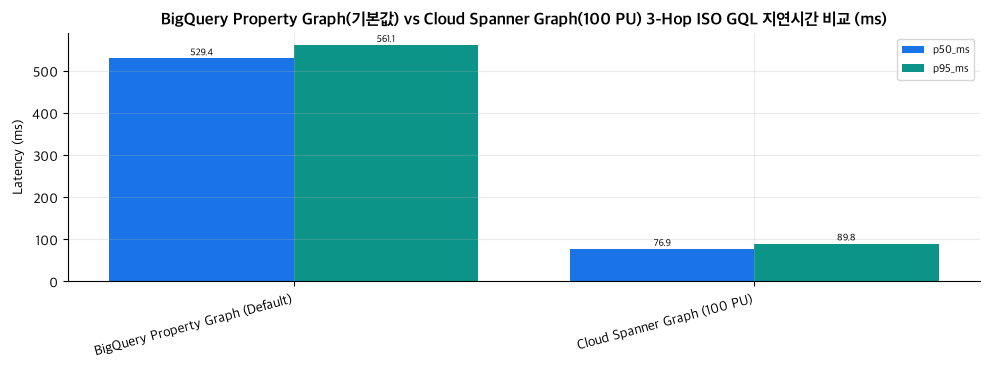

In [12]:
df_bench = H.benchmark_dual_engine_df(runs=3)
H.show(df_bench)
H.grouped_bar(df_bench, "engine", ["p50_ms", "p95_ms"],
              "BigQuery Property Graph(기본값) vs Cloud Spanner Graph(100 PU) 3-Hop ISO GQL 지연시간 비교 (ms)",
              fmt="{:,.1f}", ylabel="Latency (ms)")


In [13]:
_ = H.run_graph_fabric_federated_join()


- **Graph Fabric (`EXTERNAL_QUERY`) Execution**: status `SUCCESS` · BigQuery job `job_tfcBWlfmzCG0cD9vr-N3YgtTrpsv` · `1,509 ms` · `12 rows`

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `EXTERNAL_QUERY connection` | `seanjung-poc.asia-northeast3.spanner_fabric_conn` | BigQuery ↔ Cloud Spanner 연합 연결 리소스 |
| `Spanner Graph` | `starter-spanner/starter_ontology_db/STARTER_ONTOLOGY_GRAPH` | 원격 실행되는 온라인 프로퍼티 그래프 |
| `BigQuery Join Table` | `seanjung-poc.starter_ontology_dw.tb_doc_chunks` | SHA-256 정책 청크 원장 조인 테이블 |

**2) 실행된 Graph Fabric 연합 쿼리 (BigQuery SQL + Spanner ISO GQL Pushdown)**
```sql
SELECT
  sp.customer_id,
  sp.contract_type,
  sp.elapsed_days,
  sp.device_name,
  sp.plan_name,
  sp.monthly_fee_krw,
  sp.rule_id,
  sp.source_chunk_id,
  c.section_title,
  c.content_sha256
FROM EXTERNAL_QUERY(
  "seanjung-poc.asia-northeast3.spanner_fabric_conn",
  """GRAPH STARTER_ONTOLOGY_GRAPH
     MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode),
           (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
     RETURN c.customer_id, c.contract_type, c.elapsed_days,
            d.device_name, p.plan_name, p.monthly_fee_krw,
            r.rule_id, ap.source_chunk_id
     ORDER BY c.customer_id, r.rule_id"""
) AS sp
JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` AS c
  ON c.chunk_id = sp.source_chunk_id
ORDER BY sp.customer_id, sp.rule_id
```

,customer_id,contract_type,elapsed_days,device_name,plan_name,monthly_fee_krw,rule_id,source_chunk_id,section_title,content_sha256
0,CUST_DEMO_001,PUBLIC_SUBSIDY,120,Galaxy S26 Ultra 256GB,5G Premier Essential,85000,RULE_SIX_PLAN_180D,DOC_CHUNK_002,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0
1,CUST_DEMO_001,PUBLIC_SUBSIDY,120,Galaxy S26 Ultra 256GB,5G Premier Essential,85000,RULE_TCO_24M,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8
2,CUST_DEMO_002,PUBLIC_SUBSIDY,224,Galaxy S26 Ultra 256GB,5G Premier Super,130000,RULE_SIX_PLAN_180D,DOC_CHUNK_002,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0
3,CUST_DEMO_002,PUBLIC_SUBSIDY,224,Galaxy S26 Ultra 256GB,5G Premier Super,130000,RULE_TCO_24M,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8
4,CUST_DEMO_003,PUBLIC_SUBSIDY,88,iPhone 16 Pro 256GB,5G Premier Essential,85000,RULE_SIX_PLAN_180D,DOC_CHUNK_002,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0
5,CUST_DEMO_003,PUBLIC_SUBSIDY,88,iPhone 16 Pro 256GB,5G Premier Essential,85000,RULE_TCO_24M,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8
6,CUST_DEMO_004,SELECTIVE_25PCT,109,Galaxy S26 Ultra 512GB,5G Premier Essential,85000,RULE_SIX_PLAN_180D,DOC_CHUNK_002,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0
7,CUST_DEMO_004,SELECTIVE_25PCT,109,Galaxy S26 Ultra 512GB,5G Premier Essential,85000,RULE_TCO_24M,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8
8,CUST_DEMO_005,PUBLIC_SUBSIDY,57,iPhone 16 Pro 512GB,5G Direct 61,61000,RULE_SIX_PLAN_180D,DOC_CHUNK_002,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0
9,CUST_DEMO_005,PUBLIC_SUBSIDY,57,iPhone 16 Pro 512GB,5G Direct 61,61000,RULE_TCO_24M,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8


### Q&A
- **Q.** Zero-ETL BigQuery Property Graph(기본값)와 Cloud Spanner Graph(온라인 저지연 옵션), 그리고 Graph Fabric(`EXTERNAL_QUERY`)은 어떻게 상호보완적으로 동작하나요?
  - **A.** 원천 DW 테이블 6종과 엣지 테이블 4종은 기본값인 `BigQuery Property Graph`에서 복제 없이(Zero-ETL) 대규모 분석과 에이전트 추론을 수행하고, 실시간 저지연 포인트 탐색이 필요한 워크로드는 `Cloud Spanner Graph`(`100 PU`)에서 처리하며, `EXTERNAL_QUERY(spanner_fabric_conn)`를 통해 Spanner GQL 탐색 결과와 BigQuery `tb_doc_chunks`를 단일 SQL로 연합 조인(Graph Fabric)합니다.

### Data Analysis Key Findings
- `STARTER_ONTOLOGY_GRAPH`는 6개 노드 레이블(총 31행, 중복 키 `0건`)과 4개 엣지 레이블(총 31행)로 구성되며, 활성 연결 경로에서 25개 노드와 29개 방향성 엣지가 추출되었습니다.
- 바인딩 변수(`c.customer_id='CUST_DEMO_001'`, `t.plan_id='PLAN-5G-37'`, `elapsed_days=120`)를 적용한 ISO GQL 다이아몬드 쿼리(`GQL-04`)로 일할 위약금(`(500,000 - 200,000) × 60 / 180 = 100,000원`)을 단일 GQL 문장으로 산출했습니다.
- 양대 그래프 엔진 3회 반복 실측에서 BigQuery Property Graph(기본값)와 Cloud Spanner Graph(`starter-spanner`, `100 PU`)의 `p50`/`p95` 응답 지연시간을 정량 비교하고, `EXTERNAL_QUERY` 연합 조인으로 Spanner 그래프 탐색 결과(10행)와 BigQuery 정책 청크를 결합했습니다.

### Insights or Next Steps
- 다음 단계인 `Stage 4 (에이전트·답변)` 노트북으로 이동하여 이 Property Graph와 BigQuery/Spanner 원장을 호출하는 8종 모듈형 MCP 서버와 2-Pass AI FDE 에이전트 구축 및 답변 생성 과정을 확인하세요.

---
> **다음 학습 이동 (Navigation)**: [⬅️ Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb) ｜ [🏠 0. 전체 흐름 초기 화면](./stage0_overview_walkthrough_ko.ipynb) ｜ [➡️ Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb) ｜ [🌐 English Version](../en/stage3_property_graph_bigquery_spanner_en.ipynb) ｜ [📖 방법론 문서](../../methodology/ko/03_stage3_property_graph_ko.md)
